In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 10.8 MB/s eta 0:00:00


In [2]:
import ultralytics
ultralytics.checks()

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/112.6 GB disk)


In [3]:
from ultralytics import YOLO
from IPython.display import Image

In [4]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.5 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [5]:
from roboflow import Roboflow
rf = Roboflow(api_key="PqF6HU4FUT9iaWwYC0Yu")
project = rf.workspace("badminton-szmsf").project("safety-pyazl-6lzii")
version = project.version(1)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to safety-1 in yolov11:: 100%|██████████| 1212/1212 [00:00<00:00, 3949.48it/s]


In [6]:
dataset.location

'/content/safety-1'

In [7]:
# Train Yolo Model
!yolo task = detect mode = train data = {dataset.location}/data.yaml model = "yolo11n.pt" epochs = 100 imgsz = 640

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/safety-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimize

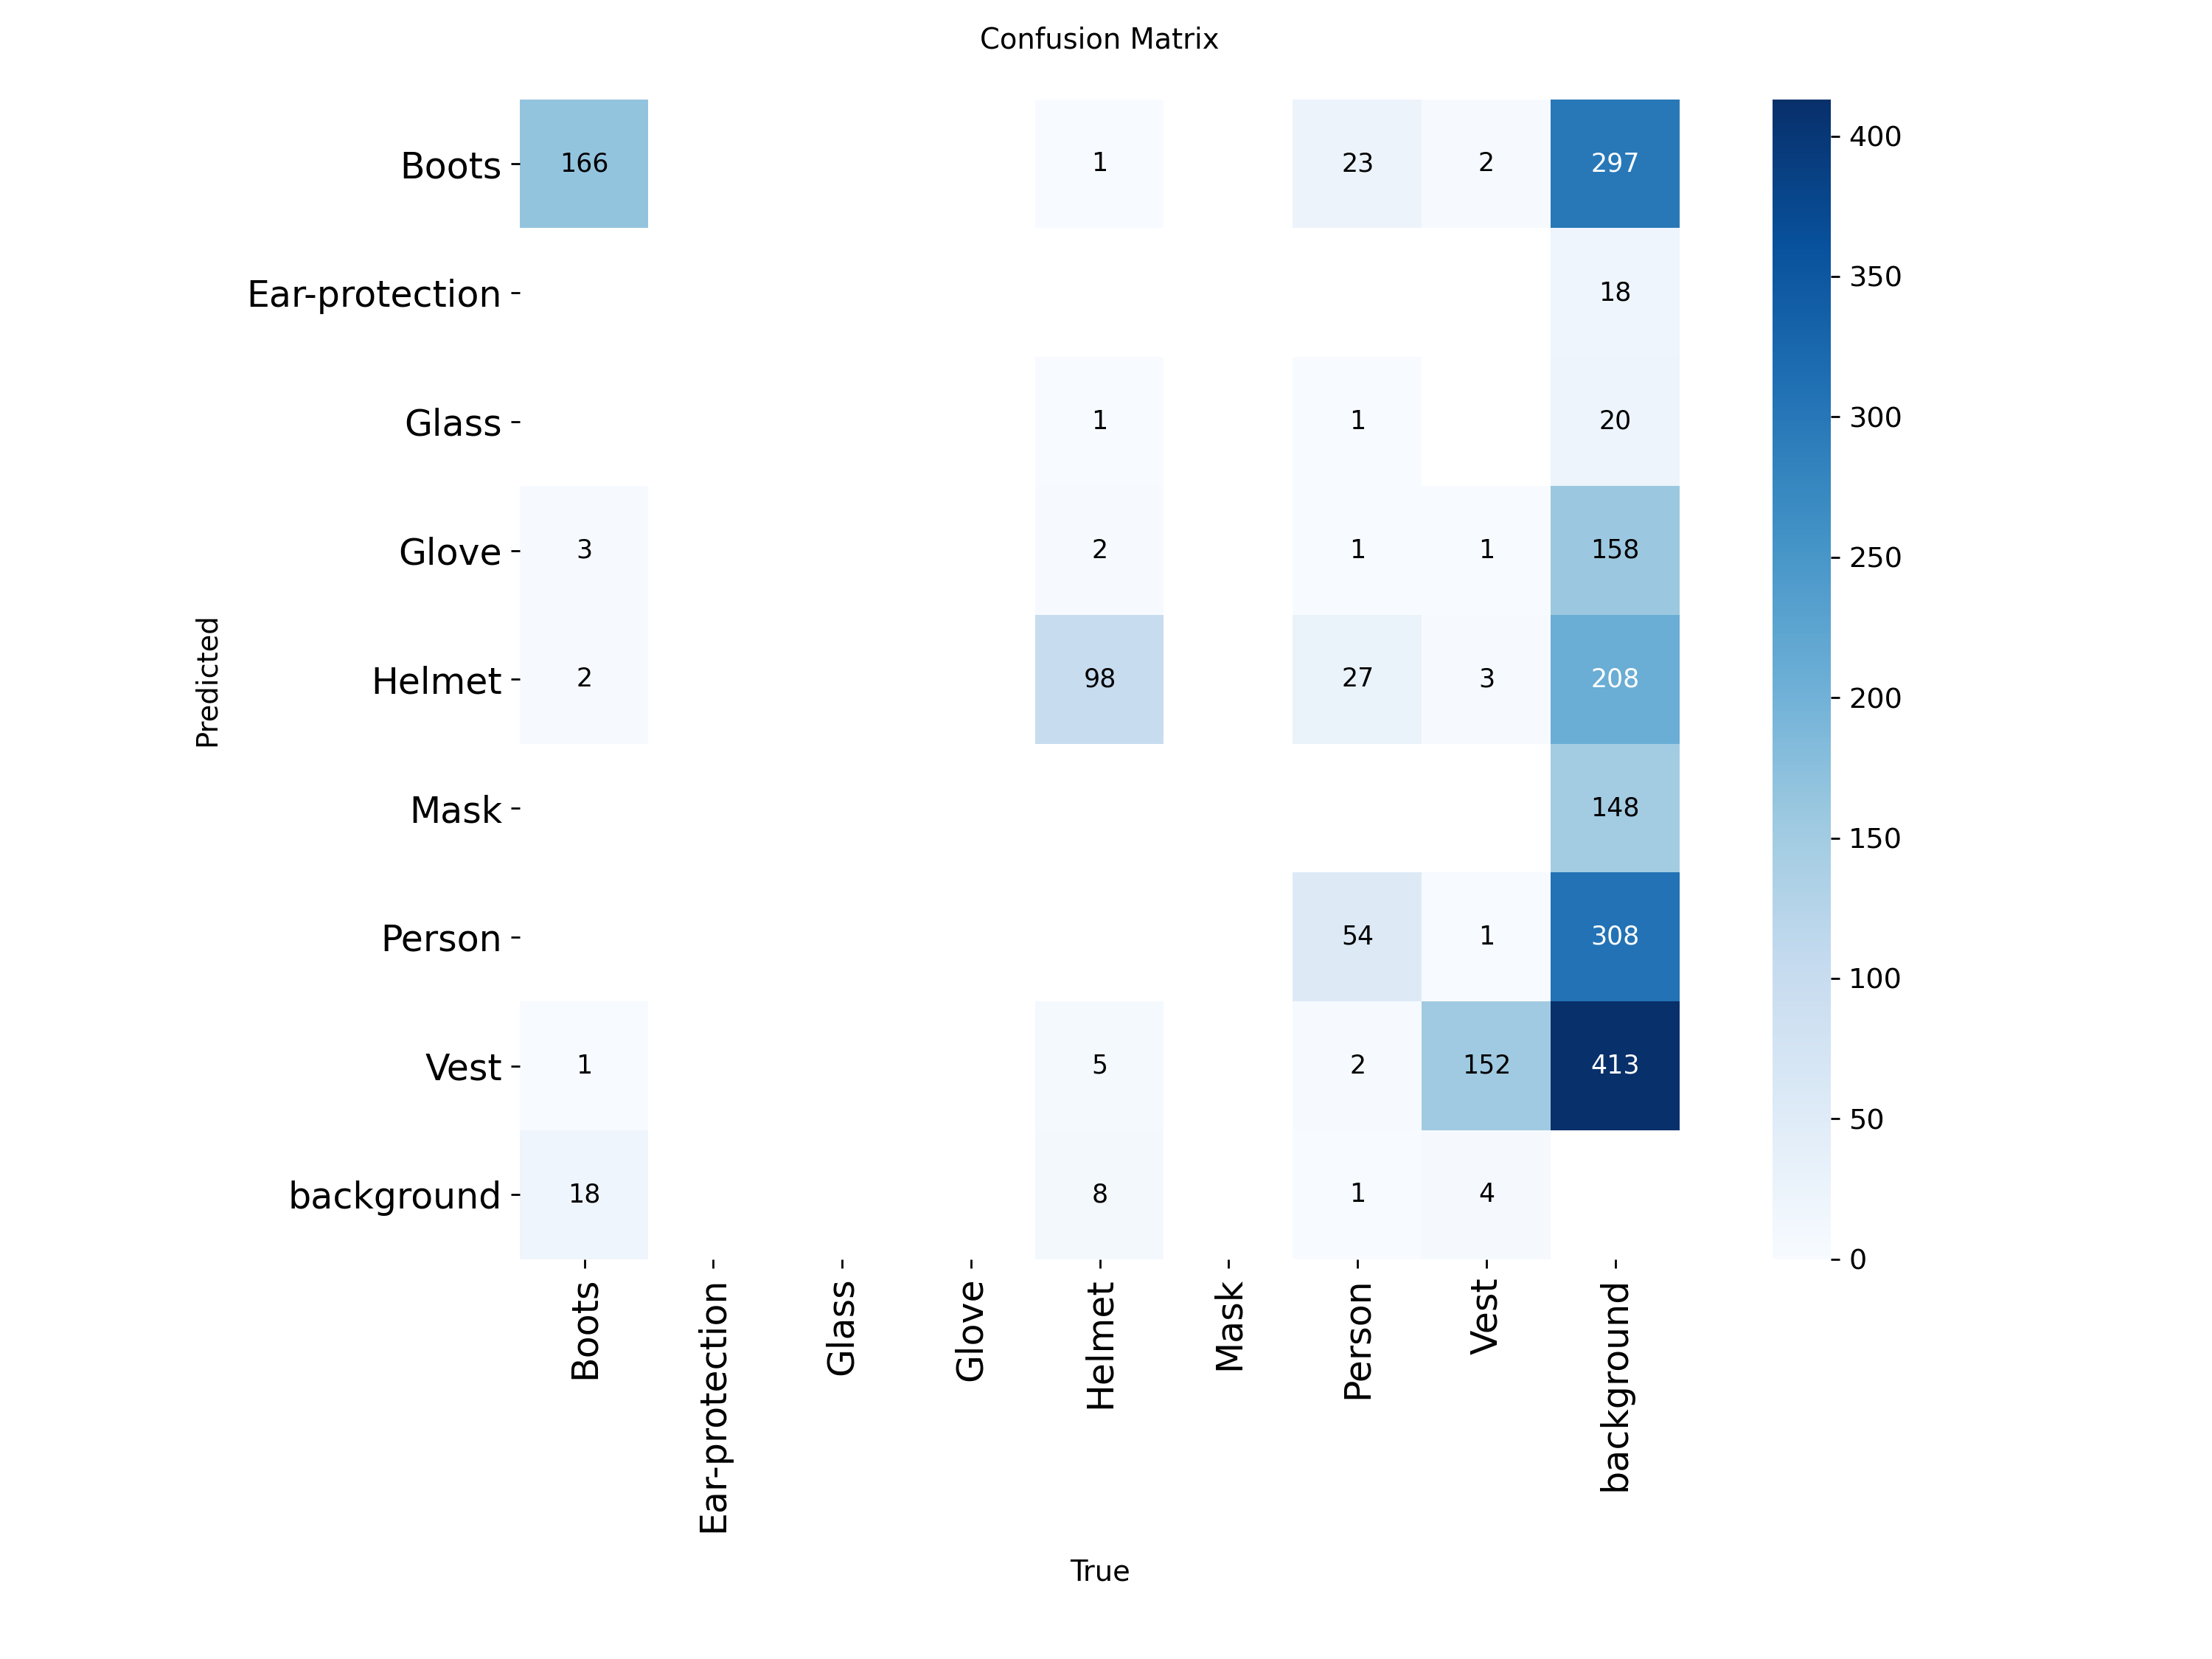

In [8]:
Image(r"/content/runs/detect/train/confusion_matrix.png", width= 800)

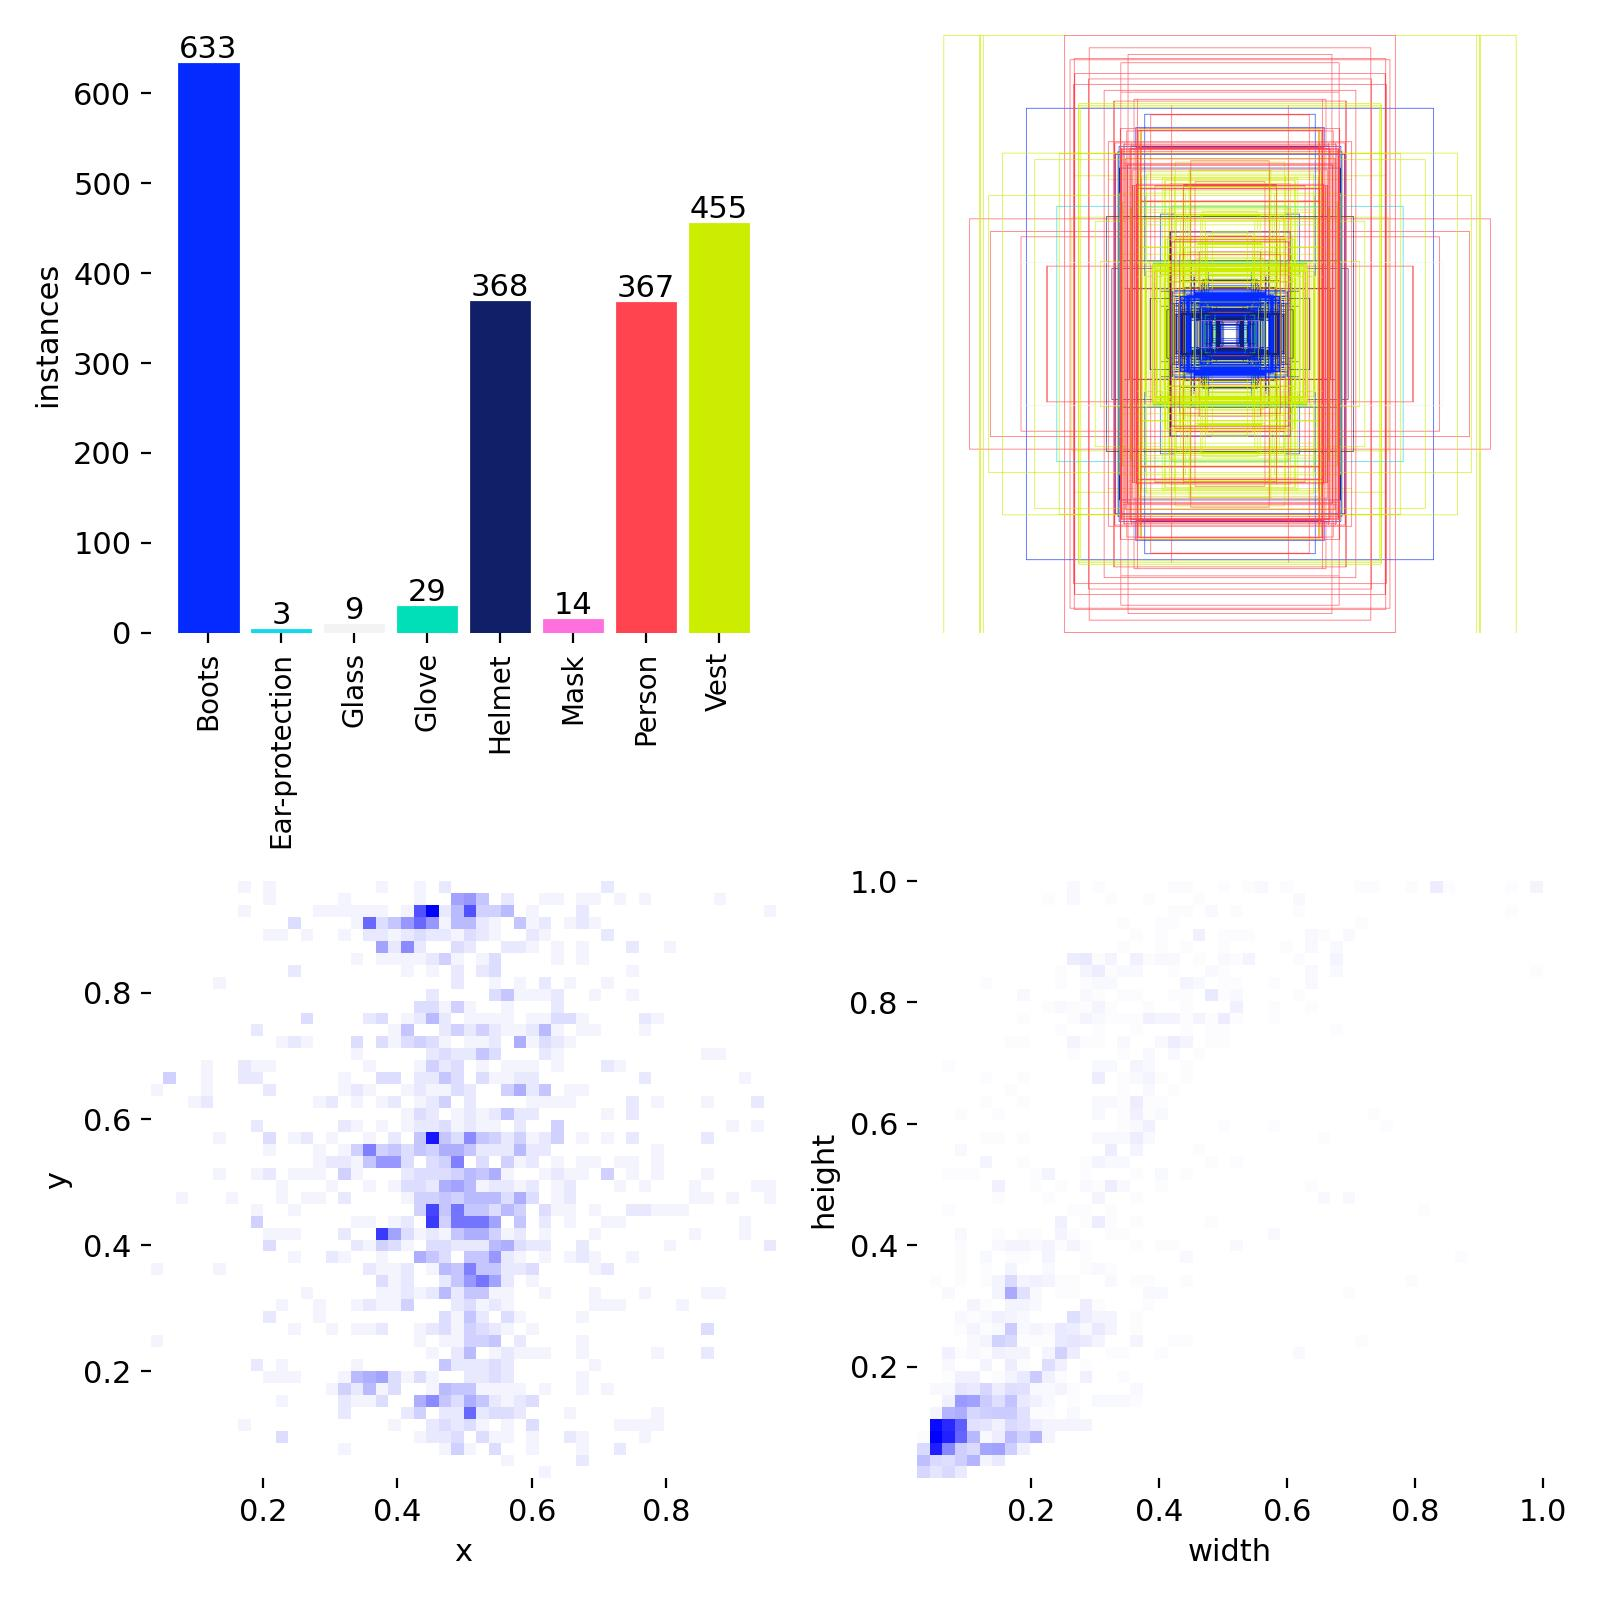

In [9]:
Image(r"/content/runs/detect/train/labels.jpg", width=600)

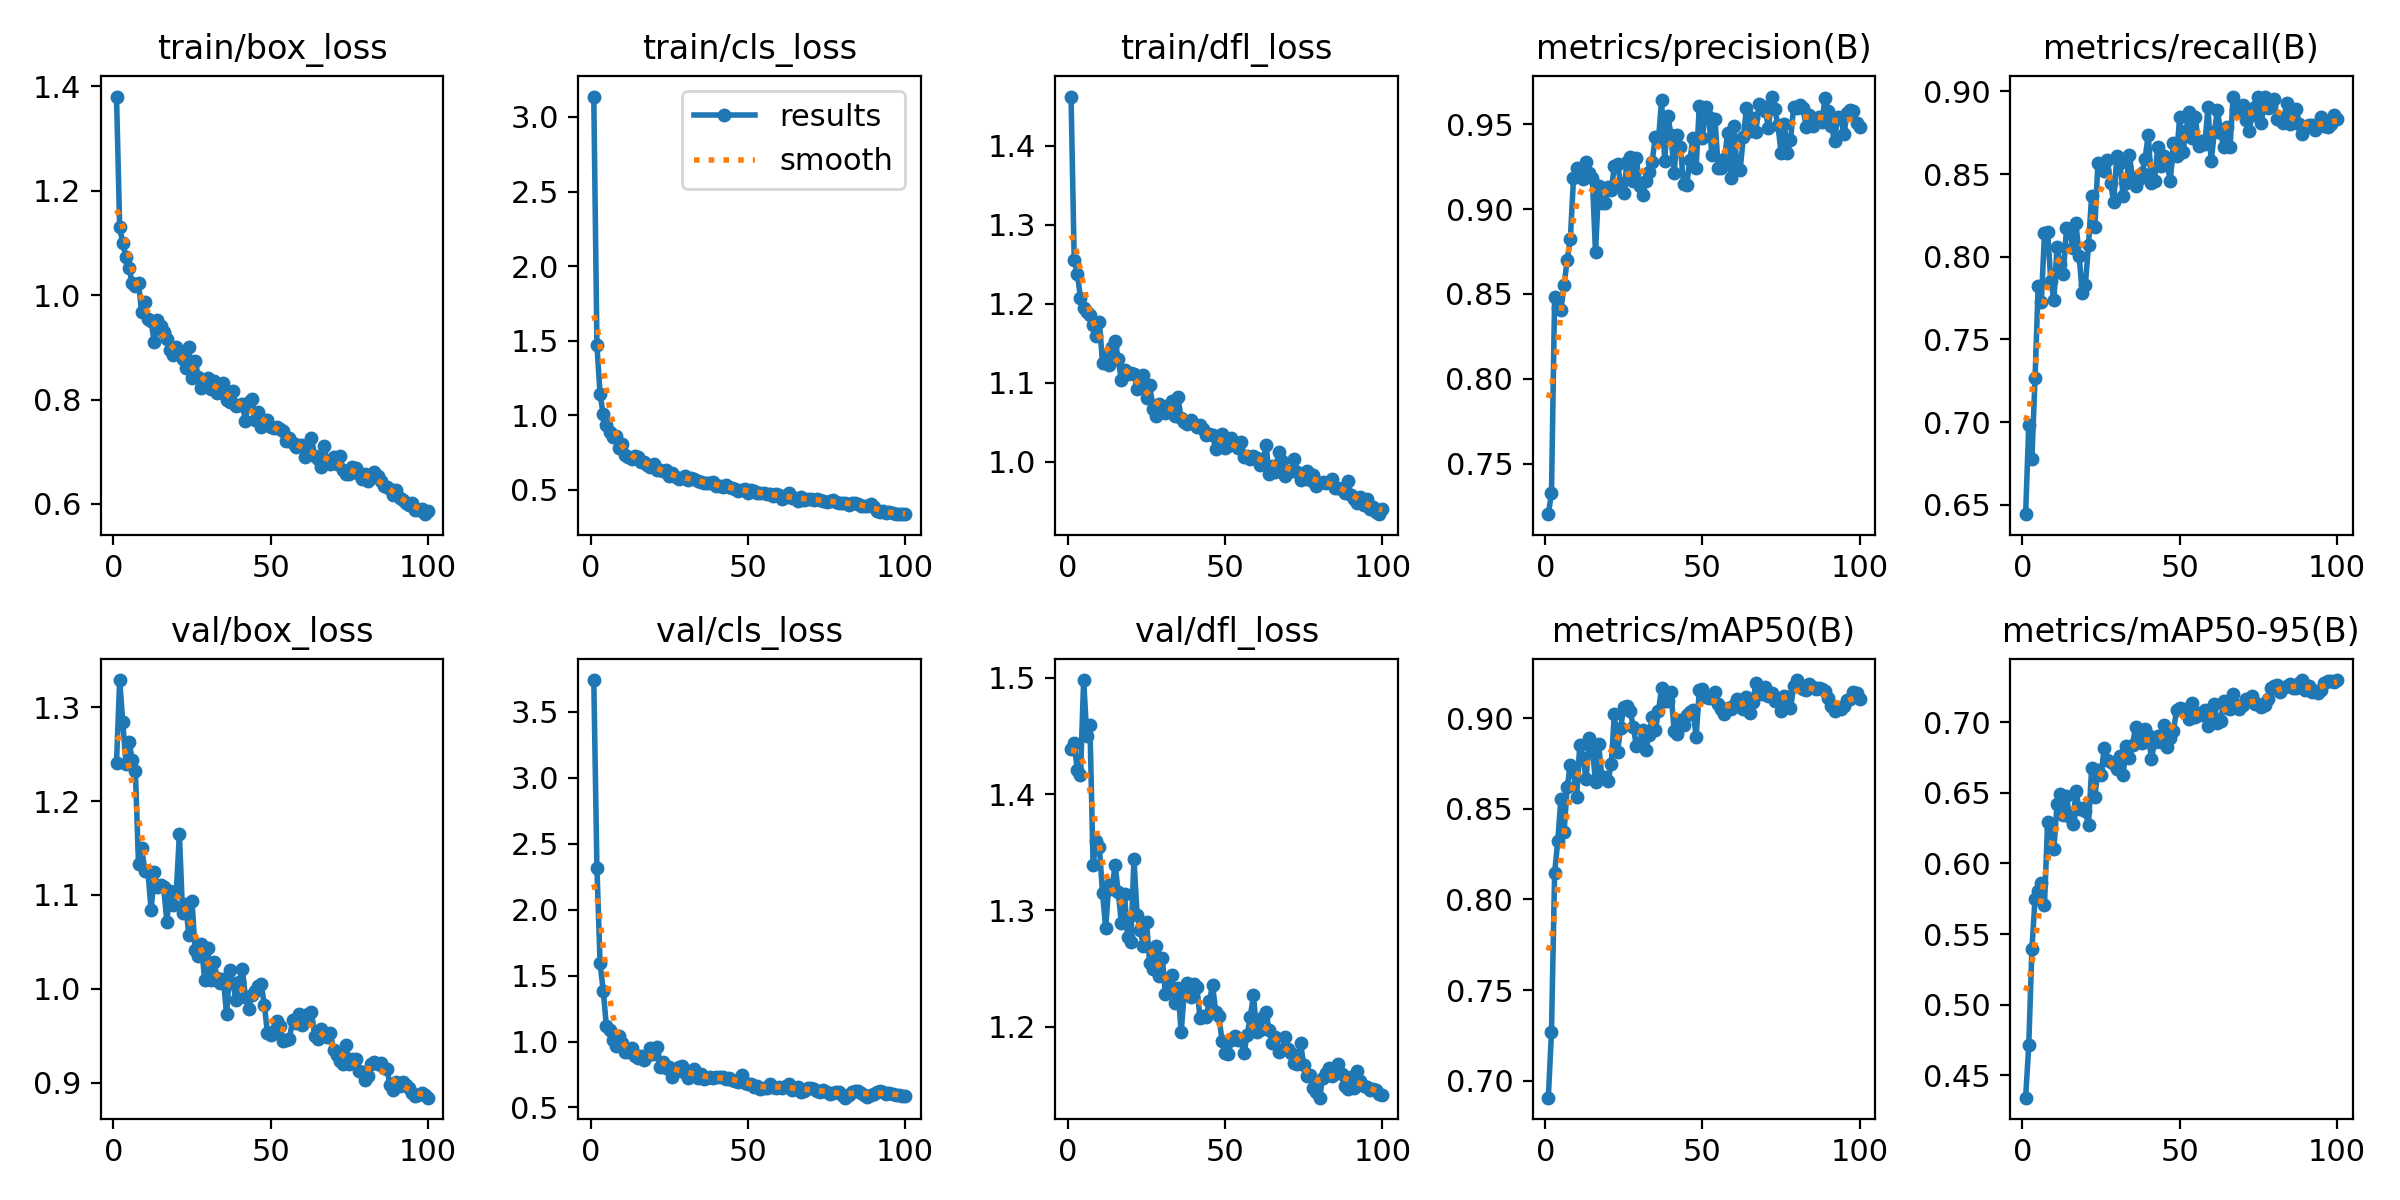

In [10]:
Image("/content/runs/detect/train/results.png", width=1000)

In [11]:
!yolo task=detect mode=val model="/content/runs/detect/train/weights/best.pt" data="/content/safety-1/data.yaml"


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,752 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2147.2±287.7 MB/s, size: 63.3 KB)
val: Scanning /content/safety-1/valid/labels.cache... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 20.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.5it/s 3.2s
                   all        120        577      0.949      0.883       0.91      0.729
                 Boots         90        190      0.946      0.823      0.865      0.653
                Helmet         89        115      0.947      0.878       0.89      0.678
                Person         96        109       0.96      0.936      0.949      0.852
                  Vest        111        163      0.942      0.896      0.936      0.733
Speed: 4.9ms preprocess, 5.8ms inference, 0.0m

In [12]:
!yolo task=detect mode=predict model="/content/runs/detect/train/weights/best.pt" conf=0.25 source="/content/safety-1/test/images" save=True


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,752 parameters, 0 gradients, 6.4 GFLOPs

image 1/60 /content/safety-1/test/images/00085_jpg.rf.e3dc30bc670cccc4e2e2898d494026e6.jpg: 640x640 1 Person, 1 Vest, 11.0ms
image 2/60 /content/safety-1/test/images/00113_jpg.rf.9189bc8144b93a5026569c25e9552aca.jpg: 640x640 1 Helmet, 1 Vest, 11.2ms
image 3/60 /content/safety-1/test/images/00126_jpg.rf.d4dfa306ff177b82ace9b8f86218e439.jpg: 640x640 1 Person, 2 Vests, 10.8ms
image 4/60 /content/safety-1/test/images/00225_jpg.rf.d6cef51757efd0b080e2ee14837ae98b.jpg: 640x640 (no detections), 11.1ms
image 5/60 /content/safety-1/test/images/00422_jpg.rf.5934171bd931a6a5831bc3f182a04e77.jpg: 640x640 1 Person, 10.8ms
image 6/60 /content/safety-1/test/images/95_JPG_jpg.rf.13543abe2764a59e8bb7e99677724cdd.jpg: 640x640 1 Helmet, 1 Person, 10.8ms
image 7/60 /content/safety-1/test/images/AightDuo0294_jpg.rf.cc7646e9e486275c64ecda983b

In [13]:
from google.colab import files

uploaded = files.upload()

Saving 0.jpg to 0.jpg



image 1/1 /content/0.jpg: 448x640 3 Helmets, 4 Persons, 3 Vests, 9.1ms
Speed: 40.0ms preprocess, 9.1ms inference, 20.0ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict-2


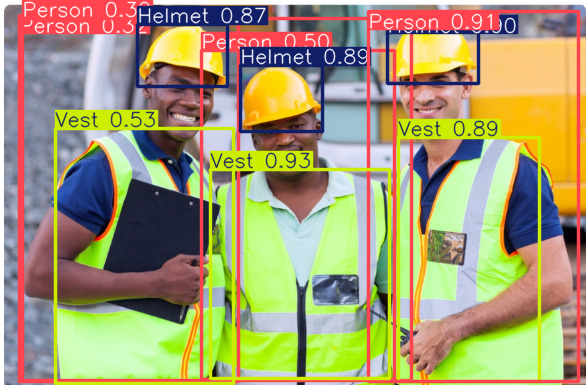

In [15]:
from ultralytics import YOLO
from IPython.display import display

# Load your trained model from the actual local run output path
model = YOLO(
    "/content/runs/detect/train/weights/best.pt"
)

# Predict
results = model.predict(
    source="/content/0.jpg",
    conf=0.25,
    save=True
)

# Display annotated image
results[0].show()

In [16]:
from google.colab import files
uploaded = files.upload()

Saving videoplayback.avi to videoplayback.avi


In [18]:
results = model.predict(
    source="/content/videoplayback.avi",
    conf=0.25,
    save=True,
    project="/content/PPE_Output",
    name="video_prediction",
    exist_ok=True
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/455) /content/videoplayback.avi: 640x384 6 Helmets, 2 Persons, 4 Vests, 142.2ms
video 1/1 (frame 2/455) /content/videoplayback.avi: 640x384 7 Helmets, 1 Person, 4 Vests, 14.1ms
video 1/1 (frame 3/455) /content/videoplayback.avi: 640x384 6 Helmets, 3 Persons, 5 Vests, 19.0ms
video 1/1 (frame 4/455) /content/videoplayback.avi: 640x384 6 Helmets, 3 Persons, 5 Vests, 18.2ms
video 1/1 (frame 5/455) /content/videoplayback.avi: 640x384 8 Helme

In [19]:
import glob
import os

video_files = glob.glob(
    "/content/PPE_Output/video_prediction/*"
)

video_files

['/content/PPE_Output/video_prediction/videoplayback.avi']

In [20]:
input_video = video_files[0]

print(input_video)

/content/PPE_Output/video_prediction/videoplayback.avi


In [21]:
output_video = "/content/PPE_prediction.mp4"

os.system(
    f'ffmpeg -y -i "{input_video}" '
    f'-c:v libx264 -c:a aac "{output_video}"'
)

print("Video converted successfully!")

Video converted successfully!


In [22]:
from IPython.display import HTML
from base64 import b64encode

video_data = open(
    "/content/PPE_prediction.mp4",
    "rb"
).read()

video_base64 = b64encode(video_data).decode()

HTML(f"""
<div style="
    width: 100%;
    max-width: 1400px;
    margin: auto;
">
    <video
        width="50%"
        controls
        style="display:block;">

        <source
            src="data:video/mp4;base64,{video_base64}"
            type="video/mp4">

    </video>
</div>
""")